# VulHunter - Graph-Only (Pure Structural)

Mode `graph_only`: Pure structural learning from NodeTypeEmbedding + R-GCN (Relational GCN).

**Kaggle 2xT4, Internet ON, FP16 mixed precision.**

## 1. Setup Environment

In [1]:
import os
import subprocess
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'


import json, math, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_auc_score, classification_report,
                             average_precision_score, precision_recall_curve, roc_curve)

sns.set_theme(style='whitegrid', context='notebook')
IS_KAGGLE = Path('/kaggle').exists()
print(f'IS_KAGGLE = {IS_KAGGLE}, PyTorch = {torch.__version__}')
if torch.cuda.is_available():
    print(f'GPUs = {torch.cuda.device_count()}')

# Clone VulHunter repo from GitHub
GITHUB_REPO = 'https://github.com/NhatWoan-20/VulHunter.git'
REPO_DIR = Path('/kaggle/working/VulHunter') if IS_KAGGLE else Path.cwd()

if not REPO_DIR.exists():
    print(f'Cloning VulHunter from GitHub to {REPO_DIR}...')
    result = subprocess.run(['git', 'clone', GITHUB_REPO, str(REPO_DIR)],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f'Clone failed: {result.stderr}')
        raise RuntimeError('Failed to clone VulHunter repo')
    print('Clone successful!')

    # Install dependencies
    print('Installing dependencies...')
    subprocess.run(['pip', 'install', '-e', str(REPO_DIR), '-q'],
                   capture_output=True)

import sys
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f'Using repo: {REPO_DIR}')

# Test imports
import importlib
errors = []
modules_to_test = [
    'src.multitask.model',
    'src.utils.dataset',
    'src.utils.losses',
    'src.utils.metrics',
    'src.semantic.encoder',
]
for mod_name in modules_to_test:
    try:
        importlib.import_module(mod_name)
    except Exception as e:
        errors.append((mod_name, e))

if errors:
    raise ImportError('Modules failed')

from src.multitask.model import VulHunterModel, ModelOutput
from src.utils.dataset import VulHunterDataset, collate_fn
from src.utils.losses import BinaryClassificationLoss
from src.utils.metrics import binary_metrics, find_best_threshold
print('All imports OK')

IS_KAGGLE = True, PyTorch = 2.11.0+cu128
GPUs = 2
Cloning VulHunter from GitHub to /kaggle/working/VulHunter...
Clone successful!
Installing dependencies...
Using repo: /kaggle/working/VulHunter
All imports OK


In [2]:
if IS_KAGGLE:
    DATA_DIR = Path("/kaggle/input/datasets/ngnhat19/vulhunter-raw-data")
    GRAPH_PATH = Path("/kaggle/input/datasets/ngnhat19/vulhunter-raw-data/master_pdg.jsonl")
else:
    DATA_DIR = REPO_DIR / "data" / "splits"
    GRAPH_PATH = REPO_DIR / "data" / "processed" / "master_pdg.jsonl"
TRAIN_JSONL = DATA_DIR / "train.jsonl"
VAL_JSONL   = DATA_DIR / "validation.jsonl"
TEST_JSONL  = DATA_DIR / "test.jsonl"
print(f"Train={TRAIN_JSONL.exists()}, Val={VAL_JSONL.exists()}, Test={TEST_JSONL.exists()}, Graph={GRAPH_PATH.exists()}")

def quick_eda(path, n=3000):
    rows = []
    with path.open() as f:
        for i, line in enumerate(f):
            if i >= n: break
            r = json.loads(line)
            rows.append({"binary_label": r.get("binary_label")})
    df = pd.DataFrame(rows)
    print(f"\nLoaded {len(df)} samples")
    print(f"Binary:\n{df['binary_label'].value_counts(normalize=True).round(3)}")
    pos_rate = df['binary_label'].mean()
    return df, 1 - pos_rate

eda_df, AUTO_FOCAL_ALPHA = quick_eda(TRAIN_JSONL)
print(f"\n🔍 auto focal_alpha = {AUTO_FOCAL_ALPHA:.3f}")

Train=True, Val=True, Test=True, Graph=True

Loaded 3000 samples
Binary:
binary_label
0    0.791
1    0.209
Name: proportion, dtype: float64

🔍 auto focal_alpha = 0.791


## 2. Configurations (Hyperparameters)

In [3]:
MODE = "graph_only"
MAX_LEN = 512
BATCH_SIZE = 256                 # Vì model nhẹ nên batch lớn
GRAD_ACCUM = 1
EPOCHS = 50                    # Graph-only hội tụ chậm hơn
LR_GRAPH = 2.0e-4              # R-GCN
LR_HEAD = 2.0e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
FOCAL_ALPHA = AUTO_FOCAL_ALPHA
FOCAL_GAMMA = 0.0
PATIENCE = 10
NUM_WORKERS = 0
USE_AMP = True
TUNE_THRESHOLD = True

GRAPH_CFG = {
    "node_feature_dim": 192,
    "hidden_dim": 192,
    "output_dim": 192,
    "num_layers": 3,
    "num_heads": 4,
    "num_edge_types": 3,
    "dropout": 0.3,
    "node_encoder_type": "none",
    "use_vul_features": False,
}
HEAD_CFG = {"binary": {"hidden_dim": 192, "dropout": 0.3}}
print(f"Mode: {MODE}")


Mode: graph_only


## 3. Initialize Model and DataLoader

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = VulHunterModel(mode=MODE, graph_config=GRAPH_CFG, head_config=HEAD_CFG)
model.to(device)
for p in model.parameters():
    if p.requires_grad and p.dtype != torch.float32: p.data = p.data.float()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"✅ [{MODE}] Trainable: {trainable:} / {total:} ({100*trainable/total:.2f}%)")

train_ds = VulHunterDataset(data_path=TRAIN_JSONL, max_length=MAX_LEN, graph_data_path=GRAPH_PATH)
val_ds   = VulHunterDataset(data_path=VAL_JSONL,   max_length=MAX_LEN, graph_data_path=GRAPH_PATH)
test_ds  = VulHunterDataset(data_path=TEST_JSONL,  max_length=MAX_LEN, graph_data_path=GRAPH_PATH)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print(f"Train: {len(train_ds):} | Val: {len(val_ds):} | Test: {len(test_ds):}")

✅ [graph_only] Trainable: 604804 / 604804 (100.00%)
Train: 111902 | Val: 13987 | Test: 13990


## 4. Optimizer & Training Functions

In [5]:
criterion = BinaryClassificationLoss(focal_alpha=FOCAL_ALPHA, focal_gamma=FOCAL_GAMMA)
graph_params, head_params = [], []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if "graph_encoder" in name: graph_params.append(p)
    else: head_params.append(p)
param_groups = []
if graph_params: param_groups.append({"params": graph_params, "lr": LR_GRAPH})
if head_params: param_groups.append({"params": head_params, "lr": LR_HEAD})
optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda s: min(1.0, s / max(1, int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)))
        if s < int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)
        else max(0.0, 0.5 * (1.0 + math.cos(math.pi * min(1.0, (s - int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)) / max(1, len(train_loader) / GRAD_ACCUM * EPOCHS - int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)))))),
)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and torch.cuda.is_available())
print(f"Optimizer: {len(graph_params)} graph + {len(head_params)} head")

Optimizer: 20 graph + 6 head


In [6]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train()
    total_loss = 0.0; n = 0
    optimizer.zero_grad(set_to_none=True)
    t0 = time.time()
    
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    for step, batch in enumerate(pbar):
        kwargs = {
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "edge_index": batch["edge_index"].to(device, non_blocking=True),
            "edge_type": batch["edge_type"].to(device, non_blocking=True),
            "batch": batch["batch"].to(device, non_blocking=True),
        }
        is_accumulating = ((step + 1) % GRAD_ACCUM != 0) and ((step + 1) != len(loader))
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
                
                # 🔴 FIX DATAPARALLEL: unpack map object
                if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
                    out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
                    
                losses = criterion(
                    binary_logits=out.binary_logits if hasattr(out, 'binary_logits') else out[0],
                    binary_targets=batch["binary_labels"].to(device),
                )
                loss = losses["total"] / GRAD_ACCUM
            scaler.scale(loss).backward()
        else:
            out = model(**kwargs)
            
            # 🔴 FIX DATAPARALLEL
            if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
                out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
                
            losses = criterion(
                binary_logits=out.binary_logits if hasattr(out, 'binary_logits') else out[0],
                binary_targets=batch["binary_labels"].to(device),
            )
            loss = losses["total"] / GRAD_ACCUM
            loss.backward()
            
        if not is_accumulating:
            if USE_AMP and scaler is not None:
                try: scaler.unscale_(optimizer)
                except ValueError:
                    for p in model.parameters():
                        if p.requires_grad and p.dtype != torch.float32: p.data = p.data.float()
                    try: scaler.unscale_(optimizer)
                    except: pass
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            
        total_loss += loss.item() * GRAD_ACCUM; n += 1
        if (step + 1) % 10 == 0 or step == len(loader) - 1:
            pbar.set_postfix({'loss': f"{total_loss/n:.4f}", 'lr': f"{optimizer.param_groups[0]['lr']:.2e}"})
            
    return total_loss / max(n, 1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_prob = [], []
    
    pbar = tqdm(loader, desc="Evaluating", leave=False)
    for batch in pbar:
        kwargs = {
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "edge_index": batch["edge_index"].to(device),
            "edge_type": batch["edge_type"].to(device),
            "batch": batch["batch"].to(device),
        }
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
        else:
            out = model(**kwargs)
            
        # 🔴 FIX DATAPARALLEL
        if hasattr(out, 'binary_logits') and type(out.binary_logits) is map:
            out.binary_logits, out.fused_embedding = tuple(out.binary_logits)
            
        binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
        p = torch.sigmoid(binary_logits.squeeze(-1))
        
        y_true.extend(batch["binary_labels"].tolist())
        y_prob.extend(p.cpu().tolist())
    return np.array(y_true), np.array(y_prob)

print("✅ Functions defined")

✅ Functions defined


In [7]:
import warnings
warnings.filterwarnings("ignore")

# Main training
best_f1 = 0.0
best_threshold = 0.5
patience_counter = 0
history = []
CKPT_DIR = Path("/kaggle/working/models/checkpoints/graph") if IS_KAGGLE else REPO_DIR / "models/checkpoints/graph"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, epoch)
    val_y, val_prob = evaluate(model, val_loader)
    elapsed = time.time() - t0

    if TUNE_THRESHOLD and len(val_y) > 0:
        thr, m = find_best_threshold(val_y, val_prob)
    else:
        thr = 0.5
        preds = (val_prob >= thr).astype(int)
        m = binary_metrics(val_y, preds, val_prob, threshold=thr)
    val_f1 = m.f1

    print(f"\nEpoch {epoch+1}/{EPOCHS} ({elapsed:.1f}s) | Train loss={train_loss:.4f} | Val F1={val_f1:.4f} | P={m.precision:.4f} | R={m.recall:.4f} | AUC={m.auc:.4f} | thr={thr:.2f}")

    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_f1": val_f1, "val_metrics": m.to_dict(), "threshold": thr, "elapsed": elapsed})

    if val_f1 > best_f1:
        best_f1 = val_f1; best_threshold = thr; patience_counter = 0
        trainable_names = {n for n, p in model.named_parameters() if p.requires_grad}
        sd = {k: v.cpu() for k, v in model.state_dict().items() if k in trainable_names}
        torch.save({
            "epoch": epoch + 1, "model_state_dict": sd,
            "best_f1": best_f1, "best_threshold": best_threshold,
            "config": {"mode": MODE, "model": {"graph": GRAPH_CFG, "heads": HEAD_CFG}},
            "history": history,
        }, CKPT_DIR / "best.pt")
        print(f"  ✅ Saved best (F1={best_f1:.4f}, thr={best_threshold:.2f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️ Early stopping.")
            break

print(f"\n✅ Best Val F1 = {best_f1:.4f} @ thr {best_threshold:.2f}")

Epoch 1/50 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]


Epoch 1/50 (113.0s) | Train loss=0.2307 | Val F1=0.3984 | P=0.2720 | R=0.7443 | AUC=0.6462 | thr=0.50
  ✅ Saved best (F1=0.3984, thr=0.50)


Epoch 2/50 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]


Epoch 42/50 (112.2s) | Train loss=0.2024 | Val F1=0.4376 | P=0.3481 | R=0.5889 | AUC=0.7060 | thr=0.70


Epoch 43/50 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]


Epoch 43/50 (111.7s) | Train loss=0.2023 | Val F1=0.4392 | P=0.3146 | R=0.7274 | AUC=0.7067 | thr=0.65

⏹️ Early stopping.

✅ Best Val F1 = 0.4413 @ thr 0.65


## 5. Test Evaluation & Diagnostics

Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]


📊 GRAPH-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET
  precision                : 0.3101
  recall                   : 0.7258
  f1                       : 0.4346
  accuracy                 : 0.5923
  support                  : 13990
  threshold                : 0.6500
  auc                      : 0.7034
  pr_auc                   : 0.3847
  mcc                      : 0.2315

📋 Báo cáo phân loại chi tiết (Classification Report):
                             precision    recall  f1-score   support

      Label 0 (Benign/Safe)     0.8804    0.5555    0.6812     10970
Label 1 (Defect/Vulnerable)     0.3101    0.7258    0.4346      3020

                   accuracy                         0.5923     13990
                  macro avg     0.5953    0.6407    0.5579     13990
               weighted avg     0.7573    0.5923    0.6280     13990



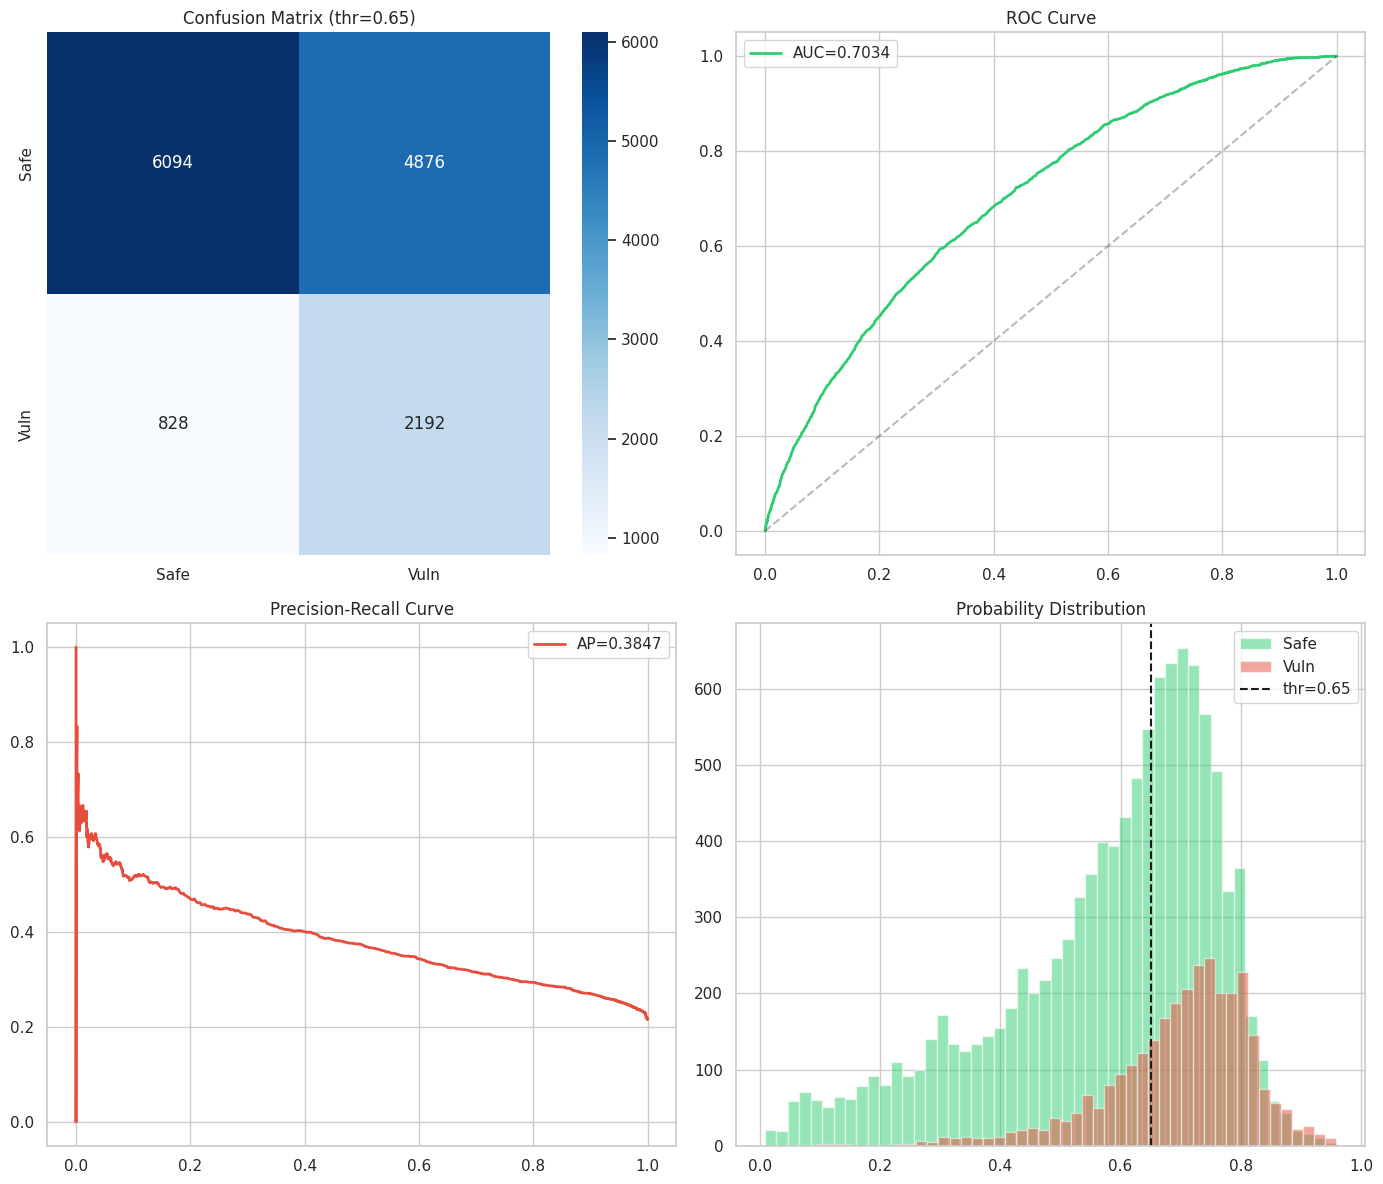

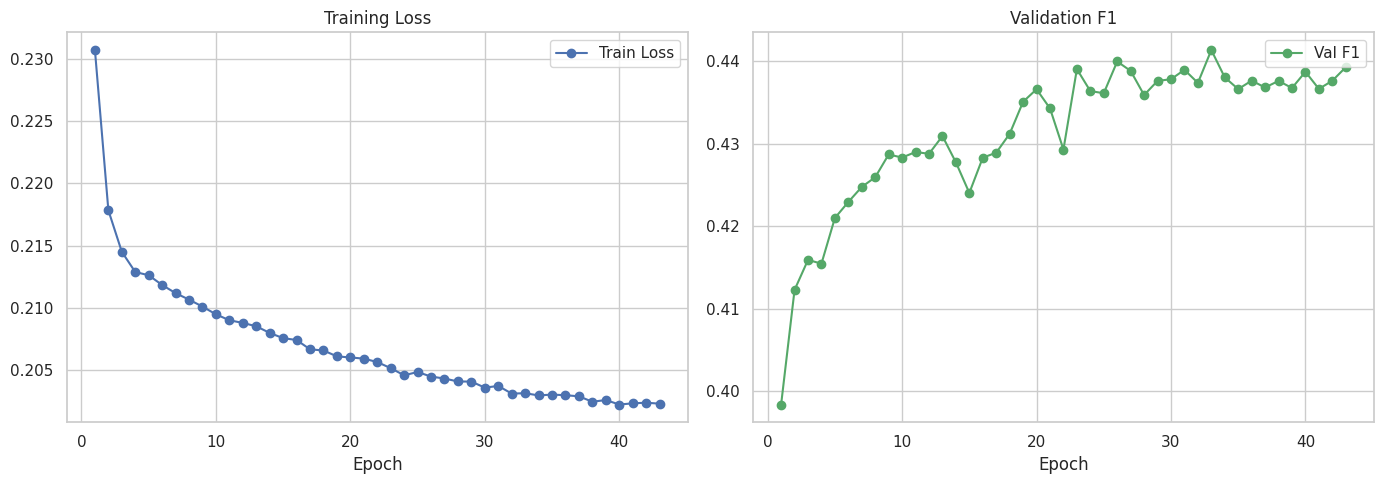

In [8]:
test_y, test_prob = evaluate(model, test_loader)
test_pred = (test_prob >= best_threshold).astype(int)
test_metrics = binary_metrics(test_y, test_pred, test_prob, threshold=best_threshold)

print("\n" + "=" * 60)
print("📊 GRAPH-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET")
print("=" * 60)
for k, v in test_metrics.to_dict().items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")
print("=" * 60)

print("\n📋 Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(
    test_y, test_pred,
    target_names=["Label 0 (Benign/Safe)", "Label 1 (Defect/Vulnerable)"],
    digits=4,
))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Confusion Matrix
cm = confusion_matrix(test_y, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0], xticklabels=["Safe", "Vuln"], yticklabels=["Safe", "Vuln"])
axes[0, 0].set_title(f"Confusion Matrix (thr={best_threshold:.2f})")

# ROC Curve
if len(np.unique(test_y)) > 1:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    axes[0, 1].plot(fpr, tpr, label=f"AUC={roc_auc_score(test_y, test_prob):.4f}", color="#2ecc71", lw=2)
    axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_title("ROC Curve")

# Precision-Recall Curve
p, r, _ = precision_recall_curve(test_y, test_prob)
axes[1, 0].plot(r, p, label=f"AP={average_precision_score(test_y, test_prob):.4f}", color="#e74c3c", lw=2)
axes[1, 0].legend()
axes[1, 0].set_title("Precision-Recall Curve")

# Probability Distribution
axes[1, 1].hist(test_prob[test_y == 0], bins=50, alpha=0.5, label="Safe", color="#2ecc71")
axes[1, 1].hist(test_prob[test_y == 1], bins=50, alpha=0.5, label="Vuln", color="#e74c3c")
axes[1, 1].axvline(best_threshold, color="k", linestyle="--", label=f"thr={best_threshold:.2f}")
axes[1, 1].legend()
axes[1, 1].set_title("Probability Distribution")

plt.tight_layout()
plt.savefig(CKPT_DIR / "diagnostics.png", dpi=120)
plt.show()

# Training History Plot (thêm vào vì semantic có)
if history:
    fig2, ax2 = plt.subplots(1, 2, figsize=(14, 5))
    epochs_done = [h["epoch"] for h in history]
    ax2[0].plot(epochs_done, [h["train_loss"] for h in history], "b-o", label="Train Loss")
    ax2[0].set_title("Training Loss")
    ax2[0].set_xlabel("Epoch")
    ax2[0].legend()
    ax2[1].plot(epochs_done, [h["val_f1"] for h in history], "g-o", label="Val F1")
    ax2[1].set_title("Validation F1")
    ax2[1].set_xlabel("Epoch")
    ax2[1].legend()
    plt.tight_layout()
    plt.savefig(CKPT_DIR / "training_history.png", dpi=120)
    plt.show()



In [9]:
summary_path = CKPT_DIR / "summary.json"
summary_path.write_text(json.dumps({
    "mode": MODE,
    "best_f1": best_f1,
    "best_threshold": best_threshold,
    "test_metrics": test_metrics.to_dict(),
    "history": history,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\n✅ Saved summary to {summary_path}")
print("🎉 Done! Đừng quên Save Version trên Kaggle.")


✅ Saved summary to /kaggle/working/models/checkpoints/graph/summary.json
🎉 Done! Đừng quên Save Version trên Kaggle.


## 6. Export Test Predictions and Archive

In [10]:
# Lưu kết quả dự đoán test set
import pandas as pd

test_results = pd.DataFrame({
    'sample_id': [s["sample_id"] for s in test_loader.dataset],
    'true_label': test_y,
    'prediction': test_pred,
    'probability': test_prob
})
csv_path = CKPT_DIR / "test_predictions.csv"
test_results.to_csv(csv_path, index=False)
print(f"✅ Đã lưu test predictions tại: {csv_path}")


✅ Đã lưu test predictions tại: /kaggle/working/models/checkpoints/graph/test_predictions.csv


In [11]:
# (Tùy chọn) Nén và tải kết quả xuống
if IS_KAGGLE:
    import shutil
    from IPython.display import FileLink, display

    output_filename = '/kaggle/working/graph_only_results'
    shutil.make_archive(
        base_name=output_filename,
        format='zip',
        root_dir=str(CKPT_DIR.parent.parent),
        base_dir='checkpoints',
    )
    display(FileLink(output_filename + '.zip'))


/kaggle/working/graph_only_results.zip